# Tugas - Medical Cost Prediction

| Nama | NRP |
|------|-----|
| Prima Surya Nusantara | 5054251036 |

## Deskripsi Tugas

Pada tugas ini, kita akan menggunakan Medical Cost Personal Dataset dari Kaggle.

Dataset:
- https://www.kaggle.com/mirichoi0218/insurance

Target yang diprediksi adalah `charges`.

Model yang digunakan:
1. Linear Regression
2. Polynomial Regression
3. Ridge Regression
4. Lasso Regression
5. Decision Tree Regressor
6. Support Vector Regression


# 1. Persiapan Dataset dan Eksplorasi Awal

In [166]:
%pip install pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [167]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [168]:
SUMBER = "insurance.csv"

df = pd.read_csv(SUMBER)

In [169]:
# Tampilkan beberapa baris pertama dataset.
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [170]:
# Tampilkan informasi dataset.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [171]:
# Periksa missing value.
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [172]:
# Tampilkan statistik deskriptif fitur numerik.
fitur_numerik = df.select_dtypes(include=['int64', 'float64'])
fitur_numerik.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [173]:
# Tampilkan jumlah nilai pada setiap fitur kategorikal.
fitur_kategorikal = df.select_dtypes(
    include=['object', 'category']
)
for kolom in fitur_kategorikal.columns:
    print(f"Jumlah nilai pada fitur '{kolom}':")
    print(fitur_kategorikal[kolom].value_counts())
    print("\n")

Jumlah nilai pada fitur 'sex':
sex
male      676
female    662
Name: count, dtype: int64


Jumlah nilai pada fitur 'smoker':
smoker
no     1064
yes     274
Name: count, dtype: int64


Jumlah nilai pada fitur 'region':
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64




C:\Users\prima\AppData\Local\Temp\ipykernel_10660\4274837818.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  fitur_kategorikal = df.select_dtypes(


## Lakukan Exploratory Data Analysis (EDA) sederhana yang diperlukan.


# 2. Preprocessing

Pisahkan fitur numerik dan kategorikal. Gunakan OneHotEncoder untuk fitur kategorikal.

Model Linear Regression, Polynomial Regression, Ridge, Lasso, dan SVR menggunakan data yang telah di-scaling. Decision Tree Regressor tidak memerlukan scaling.


In [174]:
# Pisahkan fitur (X) dan target (y).
X, y = df.drop('charges', axis=1), df['charges']


In [175]:
# Identifikasi kolom numerik dan kategorikal.
kolom_numerik = X.select_dtypes(include=['int64', 'float64']).columns
kolom_kategorikal = X.select_dtypes(include=['object']).columns

print("Kolom Numerik:", kolom_numerik)
print("Kolom Kategorikal:", kolom_kategorikal)

Kolom Numerik: Index(['age', 'bmi', 'children'], dtype='str')
Kolom Kategorikal: Index(['sex', 'smoker', 'region'], dtype='str')


C:\Users\prima\AppData\Local\Temp\ipykernel_10660\1111538214.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  kolom_kategorikal = X.select_dtypes(include=['object']).columns


In [176]:
# Bagi data menjadi train set dan test set.
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [177]:
# Buat preprocessing untuk fitur numerik dan kategorikal.
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression


pipeline_numerik = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

pipeline_kategorikal = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numerik", pipeline_numerik, kolom_numerik),
    ("kategorikal", pipeline_kategorikal, kolom_kategorikal)
])

x_train_processed = preprocessor.fit_transform(x_train)

x_test_processed = preprocessor.transform(x_test)

# 3. Eksperimen Model

## 3.1 Linear Regression

Bangun model Linear Regression menggunakan data hasil preprocessing.


In [178]:
from sklearn.linear_model import LinearRegression

model_linear = LinearRegression()
model_linear.fit(x_train_processed, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](11,)","[3614.98,2036.23, 516.89,..., 88.91,-198.28,-350.21]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.031e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](11,)","[34.92,32.9 ,30.63,..., 0. , 0. , 0. ]"


In [179]:
y_pred_linear = model_linear.predict(x_test_processed)

## 3.2 Polynomial Regression

Gunakan PolynomialFeatures. Tentukan degree berdasarkan eksperimen.


In [180]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

poly = PolynomialFeatures(degree=2, include_bias=False)

x_train_poly = poly.fit_transform(x_train_processed)
x_test_poly = poly.transform(x_test_processed)

model_poly = LinearRegression()
model_poly.fit(x_train_poly, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](77,)","[1614.1 ,2047.07, 321.08,...,-124.88, 0. , -50.59]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.005e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,77
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(36)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](77,)","[64.43,56.01,51.73,..., 0. , 0. , 0. ]"


In [181]:
y_pred_poly = model_poly.predict(x_test_poly)

## 3.3 Ridge Regression

Gunakan Ridge Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [182]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR

model_ridge = Ridge(alpha=1.0, solver="lsqr")
model_ridge.fit(x_train_processed, y_train)

,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'lsqr'
,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [183]:
y_pred_ridge = model_ridge.predict(x_test_processed)

## 3.4 Lasso Regression

Gunakan Lasso Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [184]:
model_lasso = Lasso(alpha=1.0, max_iter=10000)
model_lasso.fit(x_train_processed, y_train)

,"max_iter max_iter: int, default=1000The maximum number of iterations.",10000
,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [185]:
y_pred_lasso = model_lasso.predict(x_test_processed)

## 3.5 Decision Tree Regressor

Gunakan Decision Tree Regressor. Eksperimen dapat dilakukan pada `max_depth` dan `min_samples_leaf`.


In [186]:
# Decision Tree Regressor
from sklearn.tree import DecisionTreeRegressor
model_tree = DecisionTreeRegressor(random_state=42)
model_tree.fit(x_train_processed, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

In [187]:
y_pred_tree = model_tree.predict(x_test_processed)

## 3.6 Support Vector Regression

Gunakan SVR dengan data yang telah di-scaling. Tentukan parameter berdasarkan eksperimen.


In [188]:
# Inisialisasi dan latih SVR.
model_svr = SVR(kernel='rbf', C=100, gamma=0.1, epsilon=.1)
model_svr.fit(x_train_processed, y_train)

,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.1
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",100
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [189]:
# Lakukan prediksi pada test set.
y_pred_svr = model_svr.predict(x_test_processed)

# 4. Evaluasi Model

In [190]:
# Hitung MAE, MSE, RMSE, dan R² untuk setiap model.
# Sajikan hasil dalam satu tabel perbandingan.
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
mse_lasso = mean_squared_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mse_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)

mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

mae_linear = mean_absolute_error(y_test, y_pred_linear)
mse_linear = mean_squared_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mse_linear)
r2_linear = r2_score(y_test, y_pred_linear)

mae_poly = mean_absolute_error(y_test, y_pred_poly)
mse_poly = mean_squared_error(y_test, y_pred_poly)
rmse_poly = np.sqrt(mse_poly)
r2_poly = r2_score(y_test, y_pred_poly)

mae_tree = mean_absolute_error(y_test, y_pred_tree)
mse_tree = mean_squared_error(y_test, y_pred_tree)
rmse_tree = np.sqrt(mse_tree)
r2_tree = r2_score(y_test, y_pred_tree)

mae_svr = mean_absolute_error(y_test, y_pred_svr)
mse_svr = mean_squared_error(y_test, y_pred_svr)
rmse_svr = np.sqrt(mse_svr)
r2_svr = r2_score(y_test, y_pred_svr)

metrics_df = pd.DataFrame({
    "Model": ["Lasso", "Ridge", "Linear Regression", "Polynomial Regression", "Decision Tree", "SVR"],
    "MAE": [mae_lasso, mae_ridge, mae_linear, mae_poly, mae_tree, mae_svr],
    "MSE": [mse_lasso, mse_ridge, mse_linear, mse_poly, mse_tree, mse_svr],
    "RMSE": [rmse_lasso, rmse_ridge, rmse_linear, rmse_poly, rmse_tree, rmse_svr],
    "R²": [r2_lasso, r2_ridge, r2_linear, r2_poly, r2_tree, r2_svr]
})

display(metrics_df)

,Model,MAE,MSE,RMSE,R²
0,Lasso,4182.081076,3.360584e+07,5797.054261,0.783536
1,Ridge,4186.913490,3.362027e+07,5798.299014,0.783443
2,Linear Regression,4181.194474,3.359692e+07,5796.284659,0.783593
3,Polynomial Regression,2729.500134,2.071281e+07,4551.132385,0.866583
4,Decision Tree,3227.664954,4.446327e+07,6668.078316,0.713600
5,SVR,5807.328291,1.346078e+08,11602.061273,0.132954


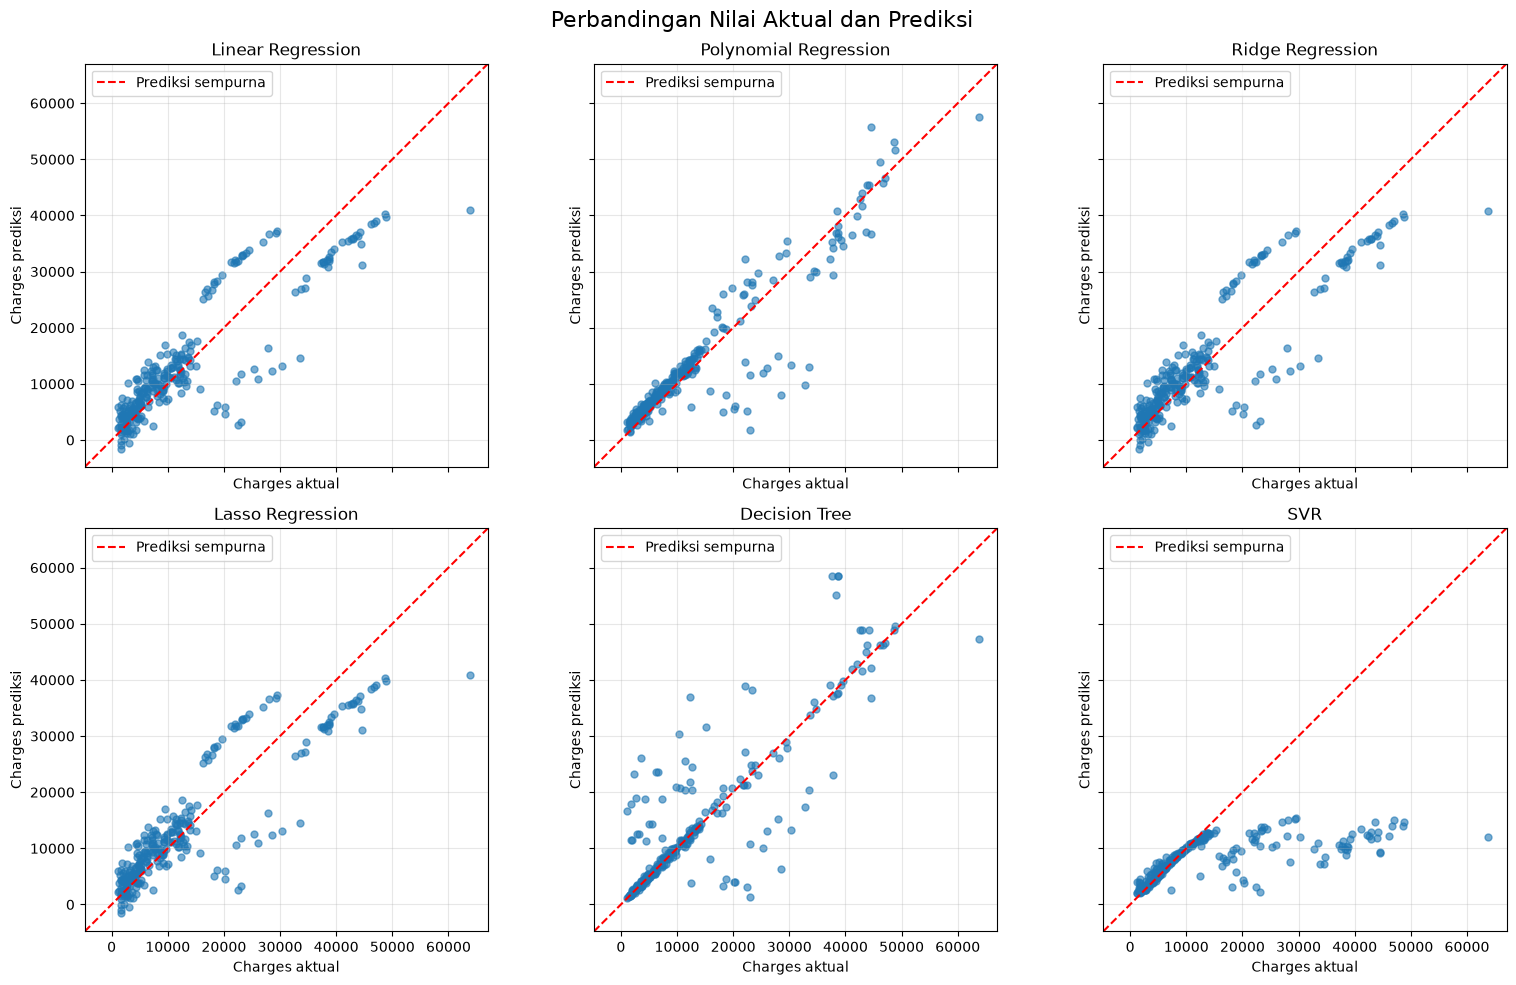

In [191]:
prediksi_model = {
    "Linear Regression": y_pred_linear,
    "Polynomial Regression": y_pred_poly,
    "Ridge Regression": y_pred_ridge,
    "Lasso Regression": y_pred_lasso,
    "Decision Tree": y_pred_tree,
    "SVR": y_pred_svr
}

# Batas sumbu yang sama agar perbandingan antar model adil.
semua_nilai = np.concatenate([
    np.asarray(y_test).ravel(),
    *[np.asarray(p).ravel() for p in prediksi_model.values()]
])

batas_min = semua_nilai.min()
batas_max = semua_nilai.max()
margin = 0.05 * (batas_max - batas_min)
batas = [batas_min - margin, batas_max + margin]

fig, axes = plt.subplots(
    2, 3, figsize=(16, 10),
    sharex=True, sharey=True
)

for ax, (nama, prediksi) in zip(axes.flat, prediksi_model.items()):
    ax.scatter(y_test, prediksi, alpha=0.6, s=25)

    # Garis prediksi sempurna: nilai prediksi = nilai aktual.
    ax.plot(batas, batas, "r--", label="Prediksi sempurna")

    ax.set_title(nama)
    ax.set_xlabel("Charges aktual")
    ax.set_ylabel("Charges prediksi")
    ax.set_xlim(batas)
    ax.set_ylim(batas)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle("Perbandingan Nilai Aktual dan Prediksi", fontsize=16)
plt.tight_layout()
plt.show()

# 5. Analisis

## 5.1 Perbandingan Hasil Model

Eksperimen menggunakan enam model untuk memprediksi biaya medis (`charges`). Dataset dibagi menjadi 80% data train dan 20% data test dengan `random_state=42`. Semua model dievaluasi pada data test yang sama menggunakan MAE, MSE, RMSE, dan R².

| Model | MAE | MSE | RMSE | R² |
|---|---:|---:|---:|---:|
| Linear Regression | 4.181,19 | 33.596.915,85 | 5.796,28 | 0,7836 |
| Polynomial Regression | 2.729,50 | 20.712.806,00 | 4.551,13 | 0,8666 |
| Ridge Regression | 4.186,91 | 33.620.271,46 | 5.798,30 | 0,7834 |
| Lasso Regression | 4.182,08 | 33.605.838,10 | 5.797,05 | 0,7835 |
| Decision Tree Regressor | 3.227,66 | 44.463.268,43 | 6.668,08 | 0,7136 |
| SVR | 5.807,33 | 134.607.825,79 | 11.602,06 | 0,1330 |

*Nilai MSE dalam tabel dibulatkan berdasarkan output notebook.*

MAE menunjukkan rata-rata selisih absolut antara prediksi dan nilai aktual. MSE dan RMSE memberikan penalti lebih besar terhadap kesalahan prediksi yang besar. Nilai ketiganya semakin kecil semakin baik, sedangkan R² semakin tinggi semakin baik.

### Polynomial Regression

Polynomial Regression derajat 2 memberikan hasil terbaik berdasarkan seluruh metrik, yaitu MAE sebesar 2.729,50, RMSE sebesar 4.551,13, dan R² sebesar 0,8666. Nilai R² tersebut menunjukkan bahwa model menjelaskan sekitar 86,66% variasi `charges` pada data test, bukan berarti persentase akurasi prediksinya sebesar 86,66%.

Dibandingkan Linear Regression, RMSE Polynomial Regression turun sekitar 21,48%. Penambahan fitur kuadrat dan interaksi membantu model menangkap pola yang belum terwakili oleh hubungan linear sederhana. Namun, hasil ini belum menunjukkan fitur atau interaksi tertentu yang paling berpengaruh.

### Linear Regression, Ridge, dan Lasso

Linear Regression, Ridge, dan Lasso menghasilkan performa yang hampir sama, dengan RMSE sekitar 5.796–5.798 dan R² sekitar 0,7834–0,7836. Linear Regression sedikit lebih baik pada eksperimen ini.

Ridge menggunakan penalti L2 untuk memperkecil koefisien, sedangkan Lasso menggunakan penalti L1 yang dapat membuat sebagian koefisien menjadi nol. Pada `alpha=1.0`, kedua metode regularisasi tersebut belum memberikan peningkatan performa test dibandingkan Linear Regression. Hasil ini tidak berarti regularisasi selalu tidak berguna; nilai `alpha` lain perlu diuji melalui validasi silang pada data train.

### Decision Tree Regressor

Decision Tree menghasilkan MAE sebesar 3.227,66, lebih rendah daripada Linear Regression. Namun, RMSE-nya lebih tinggi, yaitu 6.668,08. Perbedaan ini menunjukkan bahwa rata-rata kesalahan absolutnya lebih kecil, tetapi terdapat kesalahan besar yang memperoleh penalti lebih tinggi pada MSE dan RMSE.

Model menggunakan parameter bawaan tanpa batas `max_depth`. Kondisi tersebut memungkinkan pohon menjadi sangat kompleks. Namun, overfitting belum dapat dipastikan karena notebook belum membandingkan performa train dan test atau melakukan validasi silang.

### Support Vector Regression

SVR dengan kernel RBF, `C=100`, `gamma=0.1`, dan `epsilon=0.1` memberikan hasil terendah, dengan RMSE sebesar 11.602,06 dan R² sebesar 0,1330.

Hasil ini menunjukkan bahwa konfigurasi SVR yang digunakan belum sesuai untuk memprediksi `charges`. Salah satu kemungkinan penyebabnya adalah ketidaksesuaian parameter dengan skala target yang bernilai ribuan hingga puluhan ribu. Standardisasi fitur tidak mengubah skala target, sehingga scaling target dan tuning parameter dapat diuji pada eksperimen lanjutan.

## 5.2 Pengaruh Preprocessing

Fitur numerik (`age`, `bmi`, dan `children`) diproses menggunakan imputasi median dan StandardScaler. Fitur kategorikal (`sex`, `smoker`, dan `region`) diproses menggunakan imputasi modus dan OneHotEncoder.

Dataset tidak memiliki missing value, sehingga imputasi tidak mengisi nilai apa pun pada dataset ini. One-hot encoding memungkinkan kategori berbentuk teks digunakan oleh model. StandardScaler menyetarakan skala fitur numerik, terutama untuk model yang menggunakan regularisasi dan perhitungan jarak seperti Ridge, Lasso, dan SVR.

Preprocessing dipelajari hanya dari data train menggunakan `fit_transform()`, kemudian diterapkan pada data test menggunakan `transform()`. Cara ini mencegah informasi data test digunakan untuk menentukan parameter preprocessing.

Decision Tree juga menggunakan data hasil standardisasi, meskipun model tersebut tidak memerlukan scaling. Sementara itu, PolynomialFeatures diterapkan pada seluruh fitur hasil preprocessing, termasuk hasil one-hot encoding. Hal ini menghasilkan interaksi numerik-kategorikal, tetapi juga dapat menambahkan fitur yang redundan, seperti kuadrat kolom biner.

Pengaruh preprocessing terhadap peningkatan metrik belum dapat diukur secara langsung karena eksperimen tidak membandingkan beberapa alternatif preprocessing.

## 5.3 Batasan Eksperimen

Hasil evaluasi berasal dari satu pembagian train–test dan konfigurasi parameter yang terbatas. Oleh karena itu, Polynomial Regression merupakan model terbaik pada eksperimen ini, tetapi belum dapat dinyatakan selalu menjadi model terbaik pada pembagian data atau parameter yang berbeda.

# 6. Kesimpulan dan Saran

## 6.1 Kesimpulan

1. Preprocessing dilakukan dengan imputasi, standardisasi fitur numerik, dan one-hot encoding fitur kategorikal. Proses fitting preprocessing dilakukan hanya pada data train untuk mencegah kebocoran informasi dari data test.

2. Polynomial Regression derajat 2 menjadi model terbaik pada eksperimen ini, dengan MAE sebesar 2.729,50, RMSE sebesar 4.551,13, dan R² sebesar 0,8666. Hasil tersebut menunjukkan bahwa penambahan fitur kuadrat dan interaksi membantu prediksi biaya medis pada data test.

3. Linear Regression, Ridge, dan Lasso memberikan hasil yang hampir sama. Regularisasi dengan `alpha=1.0` belum meningkatkan performa dibandingkan Linear Regression.

4. Decision Tree memiliki MAE lebih rendah daripada Linear Regression, tetapi RMSE lebih tinggi. Dengan demikian, model ini menghasilkan rata-rata kesalahan absolut yang lebih kecil, tetapi masih memiliki kesalahan prediksi besar pada sebagian pengamatan.

5. SVR menghasilkan performa terendah pada konfigurasi yang digunakan. Hasil ini menunjukkan perlunya penyesuaian parameter dan kemungkinan scaling target, bukan bahwa SVR selalu kurang cocok untuk dataset ini.

6. Kesimpulan performa masih terbatas pada satu pembagian train–test. Diperlukan validasi tambahan untuk menilai konsistensi hasil.

## 6.2 Saran

1. **Lakukan validasi silang pada data train.** Gunakan K-Fold cross-validation untuk membandingkan model secara lebih stabil. Preprocessing perlu dimasukkan ke dalam pipeline agar dipelajari secara terpisah pada setiap fold. Simpan data test untuk evaluasi akhir.

2. **Lakukan tuning parameter.** Uji nilai `alpha` pada Ridge dan Lasso, `max_depth` serta `min_samples_leaf` pada Decision Tree, dan `C`, `gamma`, serta `epsilon` pada SVR. Pilih parameter berdasarkan hasil validasi silang, bukan berdasarkan data test.

3. **Uji scaling target untuk SVR.** Gunakan `TransformedTargetRegressor` dengan StandardScaler agar target dipelajari pada skala yang lebih sesuai. Prediksi kemudian dikembalikan ke skala biaya asli sebelum evaluasi.

4. **Evaluasi pembentukan fitur polynomial.** Bandingkan derajat polynomial melalui validasi silang dan pertimbangkan fitur interaksi yang relevan. Hindari penambahan fitur redundan secara berlebihan serta uji regularisasi pada fitur polynomial.

5. **Periksa residual dan kualitas data.** Analisis kesalahan prediksi pada biaya rendah maupun tinggi untuk mengetahui pola kesalahan model. Tinjau satu baris duplikat yang ditemukan pada dataset dan pastikan penanganannya sesuai dengan makna data. Nilai biaya ekstrem tidak perlu langsung dihapus karena dapat merupakan pengamatan yang valid.

6. **Bandingkan performa train dan test.** Perbandingan tersebut membantu mendeteksi indikasi overfitting, terutama pada Decision Tree dan model polynomial yang lebih kompleks.